# Does temperature or a seed phrase change the algorithm an LLM picks?

**Artifact `art_qJbC6mPQUr_5` (experiment), demo notebook for `method.py`.**

The experiment gives **Qwen2.5-3B-Instruct** three bare prompts and records which *algorithm* (the "idea") each generated program implements:

| task | prompt |
|---|---|
| T1 | *Implement a path search algorithm in Python* |
| T2 | *Implement a sorting algorithm* |
| T3 | *Implement a function that finds a shortest path in a weighted graph* |

Every program (13,968 in total) is labelled by a canonical classifier (BFS, DFS, Dijkstra, A*, Quick, Merge, …) and run through a sandboxed oracle. The upstream stages (vLLM generation on a GPU, labelling, oracle, statistics) write their results into `results/`. **`method.py` is the final aggregation step.** It reads those results and builds `method_out.json`, which holds four datasets and all claim verdicts:

* `c1_redraw_cells`: does temperature act like a "creativity knob"? Each (task, T, top-k) cell compares observed idea shares with a *frozen temperature law*, a fixed-utility baseline and a no-temperature-effect baseline.
* `c3_fresh_seed_strings`: does prepending a seed string (e.g. `seed=d32qxk4nt43`) change the greedy idea?
* `ban_screen_conditions`: what does the model build when the prompt bans its favourite algorithms?
* `program_ledger`: one row per program, with its label, the AST-classifier label and the oracle status.

Headline findings of the full run: the temperature law **fails** (C1), seed strings **narrow** rather than diversify ideas (C3), and the correct off-menu share stays ≤ 0.08 at every temperature.

**What this notebook runs.** The GPU stages (`--run-all`) need vLLM, a 22 GB GPU and hours of compute, so they are *not* re-run here. The notebook runs the original aggregation code of `method.py` on a curated subset (`mini_demo_data.json`): the aggregate result tables plus **100 sampled programs** of the ledger (the full ledger has 13,968). The code is the original, split into cells. The only change is that file reads go through the loaded `data` dict instead of `results/`.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru: NOT pre-installed on Colab, always install
_pip('loguru==0.7.3')

# numpy, matplotlib, pandas: pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0')

## Imports
The first block is the original import block of `method.py` (plus `math` and `numpy`, which the copied `common.py` helpers need). The plotting imports are only for the results section at the end.

In [2]:
from __future__ import annotations

import argparse
import json
import math
import subprocess
import sys
from collections import Counter
from pathlib import Path

import numpy as np
from loguru import logger

# notebook-only: results section
import pandas as pd
import matplotlib.pyplot as plt

## Data loading
`mini_demo_data.json` is fetched from the GitHub repository, falling back to a local copy. It contains:
* `results`: the aggregate result tables `method.py` reads (`temperature_law_screen.json`, `temperature_law_redraw.json`, `screen_tables.json`, `c3_scoring.json`, the frozen pre-registrations, the audits), pruned to the keys `method.py` uses;
* `labels_unified`: 100 programs sampled from `results/labels_unified.jsonl`, stratified over source × task and spread over many algorithms;
* `oracle_results`: the oracle rows of those 100 programs (from `results/oracle_results.jsonl`).

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-8d19e3-temperature-flattens-ideas-context/main/round-2/experiment-4/demo/mini_demo_data.json"
import json
from pathlib import Path

def load_data():
    try:
        import urllib.request
        with urllib.request.urlopen(GITHUB_DATA_URL) as response:
            return json.loads(response.read().decode())
    except Exception: pass
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print({k: (len(v) if isinstance(v, (list, dict)) else v) for k, v in data.items() if k != "description"})
print(sorted(data["results"]))

{'results': 12, 'labels_unified': 100, 'oracle_results': 100}
['c3_scoring.json', 'classifier_audit_ast.json', 'frozen_c1_temperature.json', 'frozen_c3_seeds.json', 'frozen_c4_reference.json', 'frozen_c4_reference_v0.json', 'judge_audit.json', 'label_repro_check.json', 'screen_tables.json', 'temperature_law_redraw.json', 'temperature_law_screen.json', 'truncation_audit.json']


## Config
* `N_LEDGER_ROWS`: how many programs of the label ledger are aggregated into the `program_ledger` dataset. The demo file holds 100. The original run used the whole ledger (13,968 programs).
* `RUN_ALL`: the original `--run-all` CLI flag. When `True`, `main()` would first run all 19 upstream stages (`src/s1_label.py` … `src/s8_figs.py`, including vLLM GPU generation). Those scripts are not part of this demo, so the flag stays `False`, which is the default `uv run method.py` behaviour (aggregate existing results only).

In [5]:
N_LEDGER_ROWS = 100   # original: all 13,968 programs in results/labels_unified.jsonl
RUN_ALL = False       # original: `uv run method.py --run-all` (GPU stages; not runnable in this notebook)

## Shared helpers (from `src/common.py`)
`method.py` imports `LABELS_PATH, ORACLE_PATH, RESULTS, read_jsonl, save_json, setup_logging` from `src/common.py`. These helpers are copied here as-is, with two notebook adaptations:
* paths are relative to the notebook's working directory;
* `read_jsonl` returns the ledger and oracle rows from the loaded `data` instead of reading the `.jsonl` files (the ledger is truncated to `N_LEDGER_ROWS`).

In [6]:
ROOT = Path(".").resolve()
RESULTS = ROOT / "results"
LOGS = ROOT / "logs"
LOGS.mkdir(parents=True, exist_ok=True)
LABELS_PATH = RESULTS / "labels_unified.jsonl"
ORACLE_PATH = RESULTS / "oracle_results.jsonl"

# notebook adaptation: the .jsonl tables come from the loaded demo data
_NB_JSONL = {LABELS_PATH.name: data["labels_unified"][:N_LEDGER_ROWS],
             ORACLE_PATH.name: data["oracle_results"]}


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(LOGS / f"{name}.log", rotation="30 MB", level="DEBUG")


def read_jsonl(p: Path) -> list[dict]:
    return list(_NB_JSONL.get(p.name, []))


def _json_default(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        f = float(o)
        return None if (math.isnan(f) or math.isinf(f)) else f
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (set, tuple)):
        return list(o)
    if isinstance(o, Path):
        return str(o.relative_to(ROOT)) if o.is_absolute() and ROOT in o.parents else str(o)
    raise TypeError(f"not serializable: {type(o)}")


def _clean(o):
    """Replace NaN/inf floats by None recursively so the JSON is strict."""
    if isinstance(o, float):
        return None if (math.isnan(o) or math.isinf(o)) else o
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, np.floating):
        return _clean(float(o))
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.ndarray):
        return _clean(o.tolist())
    if isinstance(o, np.bool_):
        return bool(o)
    return o


def save_json(p: Path, obj) -> None:
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_clean(obj), indent=1, default=_json_default))
    tmp.replace(p)

## Pipeline definition and small helpers (`method.py`)
`STAGES` is the ordered list of upstream scripts that `--run-all` executes: labelling (s1), sandboxed oracle (s2), ban-arm screen (s3), temperature law fit (s4), freezing the pre-registered predictions (`freeze.py`), GPU re-draw and seed generations (`gpu_gen.py`), truncation audit (s4b), seed readout (s6), C4 reference (s7), LLM-judge classifier audit, and figures (s8). `USER` holds the three bare prompts.

`jl` loads a result JSON or returns `None` if it is missing. Here it looks the file name up in `data["results"]`, which is the only change. `short` serialises a dict deterministically.

In [7]:
STAGES = [["src/s1_label.py"], ["src/s2_oracle.py"], ["src/s3_screen.py"], ["src/s4_templaw.py", "--source", "grid"],
          ["src/freeze.py", "c1"], ["src/gpu_gen.py", "--modes", "trunc,redraw"], ["src/s1_label.py"],
          ["src/s2_oracle.py"], ["src/s4b_truncation.py"], ["src/s4_templaw.py", "--source", "redraw"],
          ["src/s6_seed_readout.py", "--phase", "readout"], ["src/s6_seed_readout.py", "--phase", "freeze"],
          ["src/gpu_gen.py", "--modes", "seeds"], ["src/s1_label.py"], ["src/s2_oracle.py"],
          ["src/s6c_seed_score.py"], ["src/s7_c4ref.py"], ["src/judge_audit.py"], ["src/s8_figs.py"]]

USER = {"T1": "Implement a path search algorithm in Python", "T2": "Implement a sorting algorithm",
        "T3": "Implement a function that finds a shortest path in a weighted graph"}


def jl(p: Path):
    # notebook adaptation: original was `json.loads(p.read_text()) if p.exists() else None`
    return data["results"].get(p.name)


def short(d) -> str:
    return json.dumps(d, sort_keys=True)

## Dataset 1: `c1_redraw_cells` (is temperature a creativity knob?)
Claim C1 says that log idea shares are linear in 1/T (an Arrhenius-style "temperature law"). The law was fitted on the iteration-1 grid and **frozen** (hashed) before a fresh re-draw was generated. For each out-of-sample (task, top-k, T) cell, this builds one example with the observed idea shares, the frozen law's predictions (anchored and unanchored), and two baselines: a fixed-utility logit model and "temperature has no effect". The Jensen-Shannon divergence (JSD) of each prediction is stored as metadata.

In [8]:
def ds_c1(red: dict | None) -> list[dict]:
    ex = []
    if not red or "oos" not in red:
        return ex
    for key, res in red["oos"]["per_line"].items():
        task, topk = key.split("|")
        for T, v in res["by_T"].items():
            ex.append(dict(
                input=f"{USER[task]} | temperature={T} | top_k={'none' if topk == '-1' else topk} | n={v['n']} "
                      f"| classes={res['classes']}",
                output=short({k: round(x, 4) for k, x in v["observed"].items()}),
                predict_frozen_arrhenius_anchored=short({k: round(x, 4) for k, x in
                                                         v["pred_frozen_anchored"].items()}),
                predict_frozen_arrhenius_unanchored=short({k: round(x, 4) for k, x in
                                                           v["pred_frozen_unanchored"].items()}),
                predict_baseline_fixed_utility=short({k: round(x, 4) for k, x in
                                                      v["pred_baseline_fixed_utility"].items()}),
                predict_baseline_no_temperature_effect=short({k: round(x, 4) for k, x in
                                                              v["pred_baseline_no_temperature_effect"].items()}),
                metadata_task=task, metadata_T=float(T), metadata_topk=int(topk),
                metadata_jsd_frozen_anchored=v.get("jsd_frozen_anchored"),
                metadata_jsd_fixed_utility=v.get("jsd_baseline_fixed_utility"),
                metadata_jsd_no_temperature=v.get("jsd_baseline_no_temperature_effect")))
    return ex

## Dataset 2: `c3_fresh_seed_strings` (does a seed phrase push the model elsewhere?)
Claim C3: prepending a random-looking string (`seed=d32qxk4nt43`, `seed=(horse chair roof love)`, …) to the prompt shifts which idea the model picks greedily, and an internal residual-stream readout can predict the flip. Each example is one fresh seed string. It records the observed greedy idea, the readout's predicted idea, the "seed strings do nothing" baseline (the unseeded greedy label), and the T=0.7 labels for that string.

In [9]:
def ds_c3(score: dict | None, frozen: dict | None) -> list[dict]:
    ex = []
    if not score or not frozen:
        return ex
    for task, t in score.get("tasks", {}).items():
        for row in t.get("per_string", []):
            ex.append(dict(input=f"{row['seed_string']}\n\n{USER[task]}", output=str(row["observed_greedy"]),
                           predict_readout_argmax=str(row["pred_greedy_idea"]),
                           predict_baseline_unseeded_greedy=str(t["unseeded_greedy_label"]),
                           metadata_task=task, metadata_seed_kind=row["seed_kind"],
                           metadata_p_flip_readout=row["p_flip"], metadata_observed_flip=row["observed_flip"],
                           metadata_t07_labels=row["t07_labels"]))
    return ex

## Dataset 3: `ban_screen_conditions` (what happens when favourite algorithms are banned?)
In the ban arm, the prompt forbids one or more of the model's usual answers (e.g. *"do not use Quick sort"*). Each (task, condition) example stores the observed label counts, with the *placebo* condition (an irrelevant extra sentence) as the prediction to compare against. Metadata gives entropy, how often the banned idea still appears, the pass rate, and the share of correct "off-menu" programs.

In [10]:
def ds_ban(screen: dict | None) -> list[dict]:
    ex = []
    if not screen:
        return ex
    for task, conds in screen["tables"].items():
        plc = conds.get("placebo", {}).get("counts", {})
        for cond, t in conds.items():
            ex.append(dict(input=f"{USER[task]} | condition={cond} | banned={t.get('banned')}",
                           output=short(t["counts"]), predict_placebo_counts=short(plc),
                           metadata_task=task, metadata_n=t["n"], metadata_entropy_bits=t["entropy_bits"],
                           metadata_still_banned_pct=t["still_banned_pct"], metadata_pass_rate=t["pass_rate"],
                           metadata_off_menu_correct_share=t["off_menu_correct_share"]))
    return ex

## Dataset 4: `program_ledger` (one row per generated program)
This joins the unified label ledger with the oracle results on the program id. The output is the canonical v1 classifier label. The "predictions" are the AST classifier's label (graph tasks only) and the oracle status. Here the ledger is the 100-program demo subset (`N_LEDGER_ROWS`).

In [11]:
def ds_ledger() -> list[dict]:
    orc = {r["id"]: r for r in read_jsonl(ORACLE_PATH)}
    ex = []
    for r in read_jsonl(LABELS_PATH):
        o = orc.get(r["id"], {})
        ex.append(dict(input=r["id"], output=r["label"],
                       predict_ast_classifier=str(r.get("ast_label") or "n/a (sort task)"),
                       predict_oracle_status=str(o.get("status")),
                       metadata_source=r["source"], metadata_task=r["task"], metadata_cond=r["cond"],
                       metadata_T=r["T"], metadata_topk=r["topk"], metadata_wording=r["wording"],
                       metadata_finish_reason=r["finish_reason"], metadata_n_tokens=r["n_tokens"],
                       metadata_pass=o.get("passed"), metadata_still_banned=r["still_banned"]))
    return ex

## Verdicts
C1 passes only if *every eligible* (task, top-k) line passes *all* criteria on **both** the screen (iteration-1 grid) and the re-draw. The criteria are R² ≥ 0.85 for every idea line, no top-3 rank reversal at T ≤ 1.3, and an α/β slope ratio ≥ 3. The C3 verdict comes straight from the seed scoring stage.

In [12]:
def verdicts(scr, red, c3s) -> dict:
    v = {}
    if scr:
        v["C1_screen"] = scr["c1_criteria"]
    if red:
        v["C1_redraw"] = red["c1_criteria"]
        v["C1_redraw_oos_models"] = {k: x["models"] for k, x in red.get("oos", {}).get("per_line", {}).items()}
    if scr and red:
        keys = [k for k, x in scr["c1_criteria"].items() if x.get("eligible")]
        v["C1_PASS"] = all(scr["c1_criteria"][k].get("pass_all") and red["c1_criteria"].get(k, {}).get("pass_all")
                           for k in keys)
    if c3s:
        v["C3"] = c3s.get("verdict")
    return v

## `main()`: aggregate everything into `method_out.json`
This is the original `main()`. The only change is that `argparse` (`--run-all`) is replaced by the `RUN_ALL` config variable. It loads every result table, assembles the metadata (verdicts, audits, the (a)/(b)/(c) "ideas vs phrasings" tables, frozen hashes, spend) and the four datasets, then writes `method_out.json`.

In [13]:
@logger.catch(reraise=True)
def main() -> None:
    # notebook adaptation: CLI flag `--run-all` -> config variable RUN_ALL
    setup_logging("method")
    if RUN_ALL:
        for st in STAGES:
            logger.info(f"running {' '.join(st)}")
            subprocess.run([sys.executable, *st], cwd=ROOT, check=True)
    scr = jl(RESULTS / "temperature_law_screen.json")
    red = jl(RESULTS / "temperature_law_redraw.json")
    screen = jl(RESULTS / "screen_tables.json")
    c3s = jl(RESULTS / "c3_scoring.json")
    fz3 = jl(RESULTS / "frozen_c3_seeds.json")
    meta = dict(
        method_name="Unified idea ledger + temperature law (C1) + seed shocks (C3), Qwen2.5-3B-Instruct",
        model="Qwen/Qwen2.5-3B-Instruct (bf16, vLLM 0.31.0)",
        verdicts=verdicts(scr, red, c3s),
        label_repro=jl(RESULTS / "label_repro_check.json"),
        classifier_audit_ast={k: {kk: vv for kk, vv in x.items() if kk != "confusion_v1_rows_ast_cols"}
                              for k, x in (jl(RESULTS / "classifier_audit_ast.json") or {}).get("per_task_source",
                                                                                                {}).items()},
        judge_audit=(jl(RESULTS / "judge_audit.json") or {}).get("summary"),
        truncation_audit={k: v for k, v in (jl(RESULTS / "truncation_audit.json") or {}).items() if k != "logit"}
        if jl(RESULTS / "truncation_audit.json") else None,
        wording_check=(screen or {}).get("grid_vs_P1"),
        screen_regularity_candidates=(screen or {}).get("candidates"),
        abc_table_screen=(scr or {}).get("abc"), abc_table_redraw=(red or {}).get("abc"),
        hill_screen=(scr or {}).get("hill"), hill_redraw=(red or {}).get("hill"),
        repro_rows=(scr or {}).get("repro_rows", {}).get("identical_labels") if scr else None,
        c3_scoring=(c3s or {}).get("summary"),
        c4_reference=(jl(RESULTS / "frozen_c4_reference.json") or jl(RESULTS / "frozen_c4_reference_v0.json") or {})
        .get("body"),
        frozen={n: (jl(RESULTS / f"frozen_{n}.json") or {}).get("sha256") for n in
                ("c1_temperature", "c3_seeds", "c4_reference_v0", "c4_reference")},
        spend_usd=(jl(RESULTS / "judge_audit.json") or {}).get("spend_usd", 0.0),
        tables=dict(labels="results/labels_unified.jsonl", oracle="results/oracle_results.jsonl",
                    screen="results/screen_tables.json", temperature_screen="results/temperature_law_screen.json",
                    temperature_redraw="results/temperature_law_redraw.json",
                    truncation="results/truncation_audit.json", c3="results/c3_scoring.json",
                    c4="results/frozen_c4_reference.json", judge="results/judge_audit.json"))
    datasets = []
    for name, ex in (("c1_redraw_cells", ds_c1(red)), ("c3_fresh_seed_strings", ds_c3(c3s, fz3)),
                     ("ban_screen_conditions", ds_ban(screen)), ("program_ledger", ds_ledger())):
        if ex:
            datasets.append(dict(dataset=name, examples=ex))
            logger.info(f"dataset {name}: {len(ex)} examples")
    save_json(ROOT / "method_out.json", dict(metadata=meta, datasets=datasets))
    logger.info(f"wrote method_out.json; verdict keys {list(meta['verdicts'])}")
    logger.info(f"source counts {dict(Counter(r['source'] for r in read_jsonl(LABELS_PATH)))}")

In [14]:
main()

07:47:01|INFO   |dataset c1_redraw_cells: 24 examples


07:47:01|INFO   |dataset c3_fresh_seed_strings: 360 examples


07:47:01|INFO   |dataset ban_screen_conditions: 33 examples


07:47:01|INFO   |dataset program_ledger: 100 examples


07:47:01|INFO   |wrote method_out.json; verdict keys ['C1_screen', 'C1_redraw', 'C1_redraw_oos_models', 'C1_PASS', 'C3']


07:47:01|INFO   |source counts {'ban': 21, 'grid': 21, 'redraw': 21, 'seeds': 18, 'seedsfresh': 19}


## Results
We load the `method_out.json` that was just written and show:
1. the dataset sizes and the claim verdicts (C1 per line on screen and re-draw, C3);
2. **C1**: out-of-sample JSD of the frozen temperature law vs the two baselines in every re-draw cell (lower is better);
3. **C3**: how often a seed string flips the greedy idea, observed vs the two frozen predictors. The behavioural predictor was primary because the internal residual-stream readout failed its coverage gate. The table also shows the T=0.7 entropy change in bits: negative means seed strings *narrow* the ideas;
4. **Ban arm**: label counts under each ban condition vs the placebo for T2 (sorting);
5. the idea distribution of the sampled program ledger.

In [15]:
out = json.loads((ROOT / "method_out.json").read_text())
ds = {d["dataset"]: pd.DataFrame(d["examples"]) for d in out["datasets"]}
print("datasets:", {k: len(v) for k, v in ds.items()})

v = out["metadata"]["verdicts"]
print("\nC1 overall PASS:", v.get("C1_PASS"), "| C3 verdict:", v.get("C3"))
rows = []
for stage in ("C1_screen", "C1_redraw"):
    for line, c in v.get(stage, {}).items():
        rows.append(dict(stage=stage, line=line, eligible=c.get("eligible"), frac_r2_ge_085=c.get("frac_r2_ge_085"),
                         no_reversal_T_le_13=c.get("no_reversal_T_le_13"), ratio_R=c.get("ratio_R"),
                         ratio_ge_3=c.get("ratio_ge_3"), pass_all=c.get("pass_all")))
print(pd.DataFrame(rows).round(3).to_string(index=False))

datasets: {'c1_redraw_cells': 24, 'c3_fresh_seed_strings': 360, 'ban_screen_conditions': 33, 'program_ledger': 100}

C1 overall PASS: False | C3 verdict: {'C3a_T1': True, 'C3a_T2': False, 'C3b_T3': True, 'C3_PASS': False}
    stage  line  eligible  frac_r2_ge_085 no_reversal_T_le_13  ratio_R ratio_ge_3 pass_all
C1_screen T1|-1      True           0.000                True    1.149      False    False
C1_screen T1|10      True           0.667               False    1.049      False    False
C1_screen T2|-1      True           0.500                True    0.577      False    False
C1_screen T2|10      True           0.667               False    0.730      False    False
C1_screen T3|-1     False             NaN                None      NaN       None     None
C1_screen T3|10     False             NaN                None      NaN       None     None
C1_redraw T1|-1      True           0.000               False    2.636      False    False
C1_redraw T1|10      True           0.000         

Mean out-of-sample JSD per line (lower = better prediction):
               metadata_jsd_frozen_anchored  metadata_jsd_fixed_utility  metadata_jsd_no_temperature
line                                                                                                
T1 top_k=10                          0.0189                      0.0416                       0.0187
T1 top_k=none                        0.1334                      0.1600                       0.1700
T2 top_k=10                          0.0635                      0.0115                       0.0326
T2 top_k=none                        0.1196                      0.0714                       0.1000


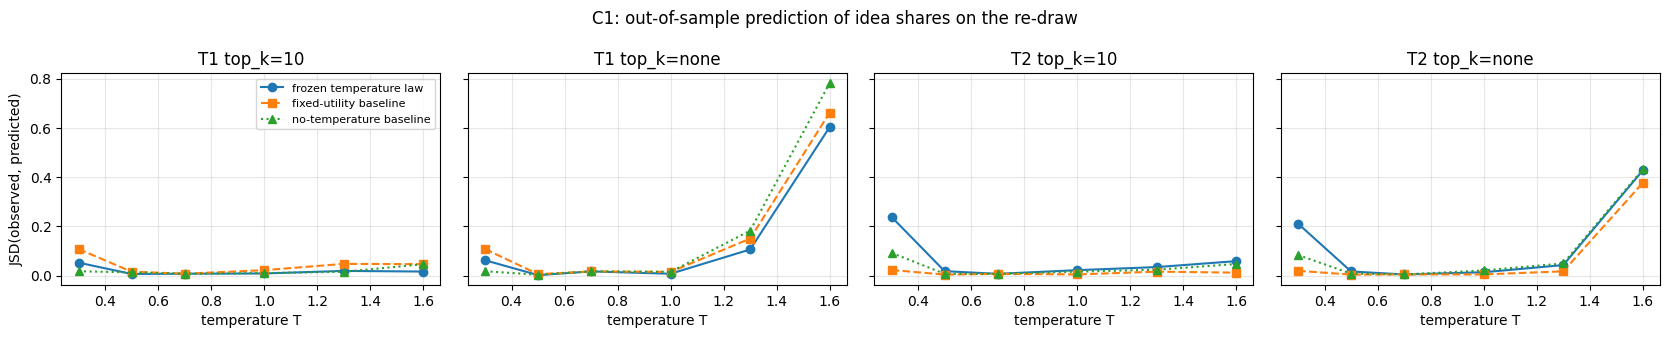

In [16]:
c1 = ds["c1_redraw_cells"].copy()
c1["line"] = c1["metadata_task"] + " top_k=" + c1["metadata_topk"].map(lambda k: "none" if k == -1 else str(k))
print("Mean out-of-sample JSD per line (lower = better prediction):")
print(c1.groupby("line")[["metadata_jsd_frozen_anchored", "metadata_jsd_fixed_utility",
                          "metadata_jsd_no_temperature"]].mean().round(4).to_string())

lines = sorted(c1["line"].unique())
fig, axes = plt.subplots(1, len(lines), figsize=(4.2 * len(lines), 3.4), sharey=True, squeeze=False)
for ax, ln in zip(axes[0], lines):
    sub = c1[c1["line"] == ln].sort_values("metadata_T")
    for col, lab, m in (("metadata_jsd_frozen_anchored", "frozen temperature law", "o-"),
                        ("metadata_jsd_fixed_utility", "fixed-utility baseline", "s--"),
                        ("metadata_jsd_no_temperature", "no-temperature baseline", "^:")):
        ax.plot(sub["metadata_T"], sub[col], m, label=lab)
    ax.set_title(ln); ax.set_xlabel("temperature T"); ax.grid(alpha=.3)
axes[0][0].set_ylabel("JSD(observed, predicted)")
axes[0][0].legend(fontsize=8)
fig.suptitle("C1: out-of-sample prediction of idea shares on the re-draw")
plt.tight_layout(); plt.show()

C3: share of seed strings that flip the greedy idea (observed vs frozen predictors)
   n_strings observed_flip_rate pred_behavioural pred_readout pred_seeds_inert      primary entropy_diff_T07_bits
T1       120               0.25          0.28073         0.95              0.0  behavioural             -0.336893
T2       120           0.016667          0.39446     0.108333              0.0  behavioural             -0.676661
T3       120                0.0          0.00004          0.0              0.0      readout              0.017776

per-string rows in the dataset, observed flip rate: {'T1': 0.25, 'T2': 0.017, 'T3': 0.0}


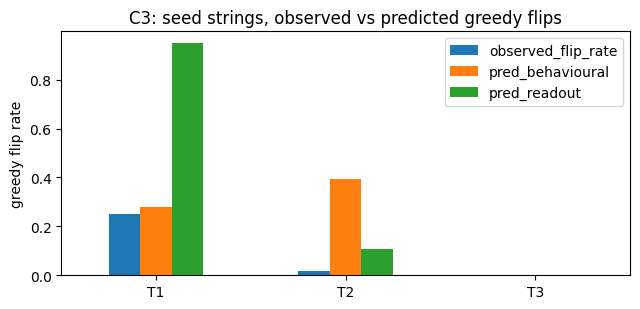

In [17]:
c3 = ds["c3_fresh_seed_strings"]
c3sum = out["metadata"]["c3_scoring"]
g = pd.DataFrame({t: dict(n_strings=x["n_strings"], observed_flip_rate=x["observed_flip_rate"],
                          pred_behavioural=x["predicted_behavioural"], pred_readout=x["predicted_readout"],
                          pred_seeds_inert=x["baseline_seeds_inert_pred"], primary=x["primary_predictor"],
                          entropy_diff_T07_bits=x.get("entropy_diff"))
                  for t, x in c3sum.items() if isinstance(x, dict) and "observed_flip_rate" in x}).T
print("C3: share of seed strings that flip the greedy idea (observed vs frozen predictors)")
print(g.to_string())
print("\nper-string rows in the dataset, observed flip rate:",
      c3.groupby("metadata_task")["metadata_observed_flip"].mean().round(3).to_dict())

ax = g[["observed_flip_rate", "pred_behavioural", "pred_readout"]].astype(float).plot.bar(figsize=(6.5, 3.2), rot=0)
ax.set_ylabel("greedy flip rate"); ax.set_title("C3: seed strings, observed vs predicted greedy flips")
plt.tight_layout(); plt.show()

metadata_task                                                                                   condition  metadata_n  metadata_entropy_bits  metadata_still_banned_pct  metadata_pass_rate  metadata_off_menu_correct_share
           T1                                                                        baseline | banned=[]         300                  1.764                        0.0               0.267                            0.003
           T1                                                                         placebo | banned=[]         100                  1.424                        0.0               0.450                            0.000
           T1                                                                     ban_r1 | banned=['BFS']         100                  1.491                        1.0               0.270                            0.000
           T1                                                                     ban_r2 | banned=['DFS']         10

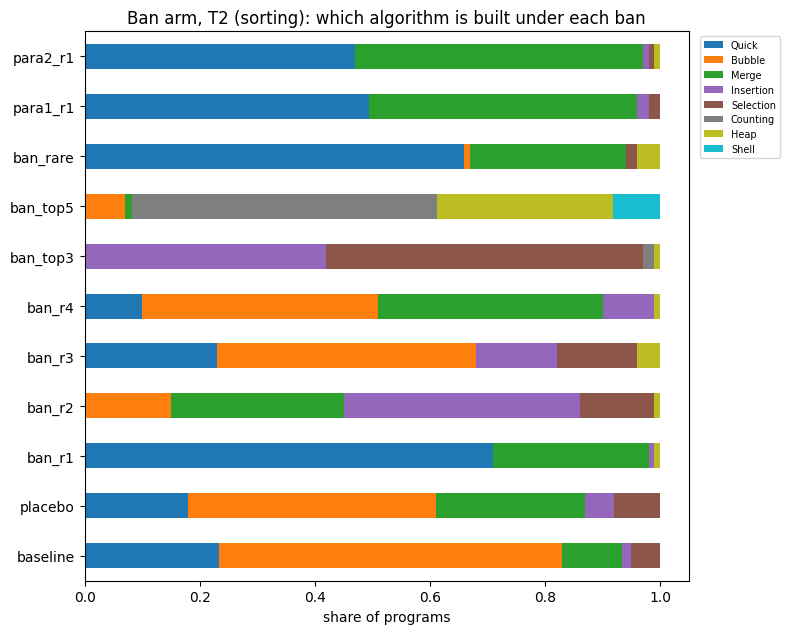

In [18]:
ban = ds["ban_screen_conditions"]
print(ban[["metadata_task", "input", "metadata_n", "metadata_entropy_bits", "metadata_still_banned_pct",
           "metadata_pass_rate", "metadata_off_menu_correct_share"]]
      .assign(input=lambda d: d["input"].str.split("condition=", regex=False).str[1])
      .rename(columns={"input": "condition"}).round(3).to_string(index=False))

t2 = ban[ban["metadata_task"] == "T2"]
counts = pd.DataFrame({r["input"].split("condition=")[1].split(" |")[0]: json.loads(r["output"])
                       for _, r in t2.iterrows()}).fillna(0).T
counts = counts[counts.sum().sort_values(ascending=False).index[:8]]
ax = (counts.div(counts.sum(axis=1), axis=0)).plot.barh(stacked=True, figsize=(8, 0.45 * len(counts) + 1.5),
                                                        colormap="tab10")
ax.set_xlabel("share of programs"); ax.set_title("Ban arm, T2 (sorting): which algorithm is built under each ban")
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

In [19]:
led = ds["program_ledger"]
print(f"Program ledger subset: {len(led)} programs")
print(pd.crosstab(led["output"], led["metadata_task"]).to_string())
print("\noracle status:", led["predict_oracle_status"].value_counts().to_dict())
graph = led[led["predict_ast_classifier"] != "n/a (sort task)"]
print(f"AST classifier agrees with v1 label on {(graph['predict_ast_classifier'] == graph['output']).mean():.2f} "
      f"of {len(graph)} graph-task programs (demo subset is label-diverse, not representative)")

Program ledger subset: 100 programs
metadata_task      T1  T2  T3
output                       
A_star              7   0   4
BFS                 6   0   5
Bellman_Ford        1   0   3
Bidirectional       2   0   1
Bubble              0   6   0
Bucket              0   2   0
Builtin             0   4   0
Counting            0   1   0
DFS                 5   0   3
Dijkstra            4   0   7
Floyd_Warshall      1   0   3
Greedy_best_first   2   0   1
Heap                0   2   0
IDDFS               1   0   0
Insertion           0   4   0
Merge               0   5   0
Other               3   5   2
Quick               0   4   0
SPFA                3   0   1
Selection           0   2   0

oracle status: {'pass': 36, 'load_error': 28, 'fail': 26, 'not_callable': 9, 'no_code': 1}
AST classifier agrees with v1 label on 0.52 of 65 graph-task programs (demo subset is label-diverse, not representative)
